# Taller de EDA · Grupo B — Precios de apartamentos en Bogotá
**Especialización en Analítica Estratégica de Datos · Machine Learning Probabilístico · Docente: Carlos Amortegui**

Metodología **CRISP-DM**, fases 1 (negocio), 2 (datos) y 3 (preparación).

**Datos de entrada** (carpeta `datos/`):

| Archivo | Contenido |
|---|---|
| `taller_habi_metrocuadrado_20260817_082346.csv` | Base del taller: 10,624 registros × 71 columnas (Habi.co + Metrocuadrado.com) |
| `casas_con_variables_osm.csv` | La misma base con 39 variables adicionales de entorno (OpenStreetMap): cercanía a salud, educación, comercio, transporte, recreación, vías, etc. |
| `estaciones_transmilenio.geojson` | 150 estaciones troncales de TransMilenio |
| `parques_bogota.geojson` | 5,315 parques de Bogotá (polígonos; se usa el centroide) |

**Salidas** (carpeta `salidas/`): `base_depurada.csv` (base limpia y legible), `train_modelado.csv` / `test_modelado.csv` (escaladas y codificadas, listas para el modelo) y `bitacora_depuracion.csv` (cuántos registros elimina cada regla).

## 1 · Entendimiento del negocio

**Problema.** Estimar el precio de venta de un apartamento en Bogotá a partir de sus características físicas, su ubicación y su entorno. Un precio mal fijado cuesta dinero en ambos sentidos: sobrevalorado, el inmueble se queda meses publicado; subvalorado, el vendedor pierde patrimonio.

**Factores que esperamos que determinen el precio**

- **Tamaño y distribución:** área construida, habitaciones, baños, parqueaderos. El área es, casi siempre, el predictor individual más fuerte.
- **Ubicación y nivel socioeconómico:** localidad, barrio y estrato. En Bogotá el estrato resume calidad del entorno, y la segregación norte/sur hace que la localidad capture gran parte de la variación del precio por m².
- **Entorno inmediato:** cercanía a TransMilenio, parques, comercio, salud y educación, y también a factores negativos (vías de alto tráfico, zonas industriales). Estas variables explican diferencias *dentro* de una misma localidad.
- **Estado y antigüedad:** nuevo, usado o remodelado; años de construido.
- **Costos y comodidades:** cuota de administración (refleja el nivel de las zonas comunes), ascensor, gimnasio, piscina, vigilancia, jacuzzi, chimenea.

**Quién se beneficia de un modelo de predicción**

- *Compradores:* identificar si un anuncio está por encima o por debajo del valor de mercado.
- *Vendedores:* fijar un precio de salida realista y reducir el tiempo de venta.
- *Inmobiliarias e iBuyers (como Habi):* valorar inventario de forma masiva y consistente, priorizar captaciones y definir márgenes.
- *Entidades financieras:* contrastar avalúos para crédito hipotecario.

**Tendencias que pueden reflejarse en los datos.** Oferta concentrada en el norte (Usaquén, Chapinero, Suba), auge de apartamentos pequeños (apartaestudios), proyectos sobre planos y vivienda VIS en la periferia occidental y sur.

**¿Tiene sentido combinar Habi con Metrocuadrado?** Son nichos distintos. Habi es un iBuyer: compra y revende apartamentos pequeños, de estratos medios, a precio ya negociado. Metrocuadrado es un portal masivo dominado por inmobiliarias, con fuerte peso de estratos 5–6 y precios *de oferta*. Habi aporta solo ~6 % de los registros, así que el modelo aprenderá sobre todo del mercado de Metrocuadrado. Decisión: **se conservan ambas fuentes**, porque Habi amplía la cobertura en el segmento medio-bajo, pero se mantiene la variable `fuente`/`tipo_vendedor` para controlar el sesgo, y la diferencia se verifica con pruebas estadísticas en la sección 2.

**Limitación estructural.** Metrocuadrado no expone dirección ni fecha de publicación. No son faltantes al azar: existen solo para Habi (~6 %). Por eso **no se imputan**; esas columnas se excluyen del modelado y la ubicación se trabaja con latitud/longitud, que sí están en ambas fuentes.

## 0 · Configuración y carga

In [1]:
import json, re, unicodedata, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

DATOS, SALIDAS = Path("datos"), Path("salidas")
SALIDAS.mkdir(exist_ok=True)
SEMILLA = 42

In [2]:
taller = pd.read_csv(DATOS / "taller_habi_metrocuadrado_20260817_082346.csv", dtype={"id": str}, low_memory=False)
osm    = pd.read_csv(DATOS / "casas_con_variables_osm.csv", dtype={"id": str}, low_memory=False)
print("Base del taller :", taller.shape)
print("Base con OSM    :", osm.shape)

Base del taller : (10624, 71)
Base con OSM    : (10510, 110)


## 2 · Unión de las variables OSM a la base del taller

La base de trabajo es **`taller_habi_metrocuadrado`**. Del archivo `casas_con_variables_osm` se toman únicamente las columnas que el taller no tiene, y se pegan con un *left join* por la llave `(fuente, id)`, de modo que no se pierde ni se duplica ningún registro del taller.

In [3]:
LLAVE = ["fuente", "id"]
assert not taller.duplicated(LLAVE).any() and not osm.duplicated(LLAVE).any(), "La llave no es única"

cols_osm = [c for c in osm.columns if c not in taller.columns]
print(f"{len(cols_osm)} variables adicionales:\n", cols_osm)

df = taller.merge(osm[LLAVE + cols_osm], on=LLAVE, how="left", validate="one_to_one", indicator="_union")
print("\nResultado de la unión:", df.shape)
print(df["_union"].value_counts().rename({"both": "con variables OSM", "left_only": "sin variables OSM"}).to_string())

39 variables adicionales:
 ['estacion', 'dist_estacion_m', 'parque', 'dist_parque_m', 'precio_m2', 'tiempo_estacion_min', 'tiempo_parque_min', 'dist_salud_m', 'salud_200m', 'salud_500m', 'dist_hospitales_clinicas_m', 'hospitales_clinicas_200m', 'hospitales_clinicas_500m', 'dist_farmacias_m', 'farmacias_200m', 'farmacias_500m', 'dist_educacion_m', 'educacion_200m', 'educacion_500m', 'dist_comercio_m', 'comercio_200m', 'comercio_500m', 'dist_transporte_m', 'transporte_200m', 'transporte_500m', 'dist_recreacion_m', 'recreacion_200m', 'recreacion_500m', 'dist_religion_m', 'religion_200m', 'religion_500m', 'dist_factores_negativos_m', 'factores_negativos_200m', 'factores_negativos_500m', 'via_principal_cercana', 'tipo_via_principal_cercana', 'dist_via_principal_m', 'vias_principales_200m', 'vias_principales_500m']

Resultado de la unión: (10624, 111)
_union
con variables OSM    10510
sin variables OSM      114
right_only               0


In [4]:
# ¿Quiénes son los registros del taller que no tienen variables OSM?
sin_osm = df[df["_union"] == "left_only"]
sin_coord = sin_osm["latitud"].isna() | (sin_osm["latitud"] == 0)
fuera = ~sin_coord & ~(sin_osm["latitud"].between(4.45, 4.84) & sin_osm["longitud"].between(-74.23, -73.99))
print(f"De {len(sin_osm)}: sin coordenadas o con (0, 0) = {sin_coord.sum()} | con coordenadas fuera de Bogotá = {fuera.sum()} "
      f"| dentro de Bogotá = {(~sin_coord & ~fuera).sum()}")
sin_osm[["fuente", "id", "localidad", "barrio", "latitud", "longitud"]].head(8)

De 114: sin coordenadas o con (0, 0) = 92 | con coordenadas fuera de Bogotá = 22 | dentro de Bogotá = 0


,fuente,id,localidad,barrio,latitud,longitud
73,habi.co,27740,LOS MARTIRES,La Sabana,4.73,-74.28
751,metrocuadrado.com,MC6748295,NaN,SANTA CECILIA,NaN,NaN
777,metrocuadrado.com,5545-M6502778,NaN,NaN,NaN,NaN
1078,metrocuadrado.com,MC6954647,NaN,CEDRITOS,NaN,NaN
1308,metrocuadrado.com,12496-M5475432,NaN,NaN,0.00,0.00
1329,metrocuadrado.com,MC2648193,NaN,CERRITOS PEREIRA,NaN,NaN
1478,metrocuadrado.com,MC6958080,NaN,SUBA PINOS DE LOMBARDIA ALTOS DE SUBA Y CERR...,NaN,NaN
1571,metrocuadrado.com,16040-M6643354,NaN,NaN,0.00,0.00


Los 114 registros sin variables OSM son los que **no tienen una ubicación utilizable**: coordenadas nulas, en `(0, 0)` o fuera de Bogotá. Sin ubicación no se puede calcular ninguna variable de entorno. No se eliminan aquí: salen más adelante con la regla de coordenadas válidas, y al final se verifica que la base depurada no tenga nulos en las variables OSM.

## 3 · Cálculo de distancias con Haversine

El taller pide calcular, para cada apartamento, la distancia al parque y a la estación de TransMilenio más cercanos:

$$a = \sin^2\!\left(\tfrac{\Delta lat}{2}\right) + \cos(lat_1)\cos(lat_2)\sin^2\!\left(\tfrac{\Delta lon}{2}\right),\qquad c = 2\,\mathrm{atan2}(\sqrt{a},\sqrt{1-a}),\qquad d = R\,c,\quad R = 6{,}371{,}000\ \text{m}$$

In [5]:
R_TIERRA = 6_371_000  # metros

def haversine(lat1, lon1, lat2, lon2):
    # Distancia en metros entre puntos (en grados). Acepta escalares o arreglos numpy (broadcasting).
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))   # grados -> radianes
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return R_TIERRA * c

# Verificación con el ejemplo del enunciado (Edificio Claudia Cecilia -> estación Calle 100): ~600 m
print(f"Ejemplo del enunciado: {haversine(4.680549, -74.053510, 4.683949, -74.057712):,.0f} m")

Ejemplo del enunciado: 600 m


In [6]:
# --- Estaciones de TransMilenio (puntos) ---
gj = json.load(open(DATOS / "estaciones_transmilenio.geojson", encoding="utf-8"))
estaciones = pd.DataFrame([{"nombre": f["properties"]["nom_est"],
                            "longitud": f["geometry"]["coordinates"][0],
                            "latitud": f["geometry"]["coordinates"][1]} for f in gj["features"]])

# --- Parques (polígonos): se calcula el centroide ponderado por área de cada parque ---
def centroide(geom):
    polis = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
    A = cx = cy = 0.0
    for poli in polis:
        xy = np.asarray(poli[0], dtype=float)[:, :2]             # anillo exterior
        x, y = xy[:, 0], xy[:, 1]
        cruz = x[:-1] * y[1:] - x[1:] * y[:-1]
        a = cruz.sum() / 2
        if abs(a) < 1e-14:
            continue
        cx += ((x[:-1] + x[1:]) * cruz).sum() / 6
        cy += ((y[:-1] + y[1:]) * cruz).sum() / 6
        A += a
    if A == 0:                                                    # polígono degenerado: promedio de vértices
        xy = np.asarray(polis[0][0], dtype=float)[:, :2]
        return xy[:, 0].mean(), xy[:, 1].mean()
    return cx / A, cy / A

gj = json.load(open(DATOS / "parques_bogota.geojson", encoding="utf-8"))
parques = pd.DataFrame([{"nombre": f["properties"]["Nombre_Par"], **dict(zip(("longitud", "latitud"), centroide(f["geometry"])))}
                        for f in gj["features"]])

# Cerca de la mitad de los nombres de parque vienen con la codificación dañada desde la fuente (p. ej. 'URBANIZACIàN'):
# son bytes cp850 leídos como latin-1. Se reparan solo los nombres que muestran ese síntoma.
def reparar_nombre(s):
    if isinstance(s, str) and re.search("[àÖ¥µ\x90]", s):
        try:
            return s.encode("latin-1").decode("cp850")
        except (UnicodeEncodeError, UnicodeDecodeError):
            return s
    return s
parques["nombre"] = parques["nombre"].map(reparar_nombre)
print(f"{len(estaciones)} estaciones y {len(parques):,} parques")

150 estaciones y 5,315 parques


In [7]:
def mas_cercano(lat, lon, ref, bloque=1000):
    # Distancia mínima (m) y nombre del punto de `ref` más cercano a cada apartamento. Vectorizado por bloques.
    dist, nombre = np.full(len(lat), np.nan), np.full(len(lat), None, dtype=object)
    rlat, rlon, rnom = ref["latitud"].values, ref["longitud"].values, ref["nombre"].values
    validos = np.flatnonzero(~np.isnan(lat) & ~np.isnan(lon))
    for i in range(0, len(validos), bloque):
        idx = validos[i:i + bloque]
        d = haversine(lat[idx, None], lon[idx, None], rlat[None, :], rlon[None, :])   # matriz apartamentos x referencias
        j = d.argmin(axis=1)
        dist[idx], nombre[idx] = d[np.arange(len(idx)), j], rnom[j]
    return dist, nombre

lat, lon = df["latitud"].to_numpy(float), df["longitud"].to_numpy(float)
df["distancia_parque_mas_cercano_m"], df["parque_mas_cercano"] = mas_cercano(lat, lon, parques)
df["distancia_transmilenio_mas_cercana_m"], df["estacion_mas_cercana"] = mas_cercano(lat, lon, estaciones)

df.loc[df["titulo"].str.contains("Claudia Cecilia", na=False),
       ["titulo", "estacion_mas_cercana", "distancia_transmilenio_mas_cercana_m", "estacion", "dist_estacion_m",
        "parque_mas_cercano", "distancia_parque_mas_cercano_m", "dist_parque_m"]]

,titulo,estacion_mas_cercana,distancia_transmilenio_mas_cercana_m,estacion,dist_estacion_m,parque_mas_cercano,distancia_parque_mas_cercano_m,dist_parque_m
0,Edificio Claudia Cecilia - Apartamento en Vent...,Calle 100 - Marketmedios,599.88,Virrey,"1,303.60",CHICO NORTE,109.75,337.00


El resultado reproduce el ejemplo del enunciado (estación *Calle 100*, ≈ 600 m).

**Haversine vs. variables OSM.** El archivo OSM ya trae `dist_estacion_m` y `dist_parque_m`, pero miden otra cosa: `dist_estacion_m` es consistentemente mayor (para el mismo apartamento reporta 1,304 m a *Virrey*), compatible con una distancia por red peatonal, y `dist_parque_m` vale 0 en cientos de casos, es decir, mide distancia al *borde* del parque y no al centroide. Se conservan ambas familias en la base depurada; para el modelado se revisa su correlación más abajo.

## 4 · Entendimiento de los datos (EDA sobre la base cruda)
### 4.1 Dimensiones, tipos y nulos

In [8]:
print(f"Registros: {len(df):,} | Columnas: {df.shape[1] - 1} (71 del taller + {len(cols_osm)} OSM + 4 de Haversine)")
print("\nTipos de dato:\n", df.drop(columns="_union").dtypes.astype(str).value_counts().to_string())
print("\nRegistros por fuente:\n", df["fuente"].value_counts().to_string())
print("\nTipo de propiedad:\n", df.groupby("fuente")["tipo_propiedad"].value_counts().to_string())

Registros: 10,624 | Columnas: 114 (71 del taller + 39 OSM + 4 de Haversine)

Tipos de dato:
 float64    63
str        44
int64       4
object      3

Registros por fuente:
 fuente
metrocuadrado.com    10013
habi.co                611

Tipo de propiedad:
 fuente             tipo_propiedad
habi.co            Apartamento         572
                   Casa                 39
metrocuadrado.com  Apartamento       10013


In [9]:
nulos = (df.drop(columns="_union").isna().mean() * 100).sort_values(ascending=False)
nulos_fuente = df.drop(columns="_union").isna().groupby(df["fuente"]).mean().T * 100
tabla_nulos = pd.concat([nulos.rename("% nulos total"), nulos_fuente.add_prefix("% nulos ")], axis=1)
print(f"Columnas con algún nulo: {(nulos > 0).sum()} | con más de 90 % de nulos: {(nulos > 90).sum()}")
tabla_nulos[tabla_nulos["% nulos total"] > 0].head(45)

Columnas con algún nulo: 101 | con más de 90 % de nulos: 31


,% nulos total,% nulos habi.co,% nulos metrocuadrado.com
num_deposito,99.56,92.31,100.00
num_parqueadero,98.86,80.20,100.00
tipo_vivienda,98.06,100.00,97.94
nombre_proyecto,98.06,100.00,97.94
discount_rate,97.84,62.36,100.00
discount,97.67,59.41,100.00
previous_price,97.62,58.59,100.00
price_observation,97.62,58.59,100.00
lot_id,94.53,4.91,100.00
slug,94.29,0.65,100.00


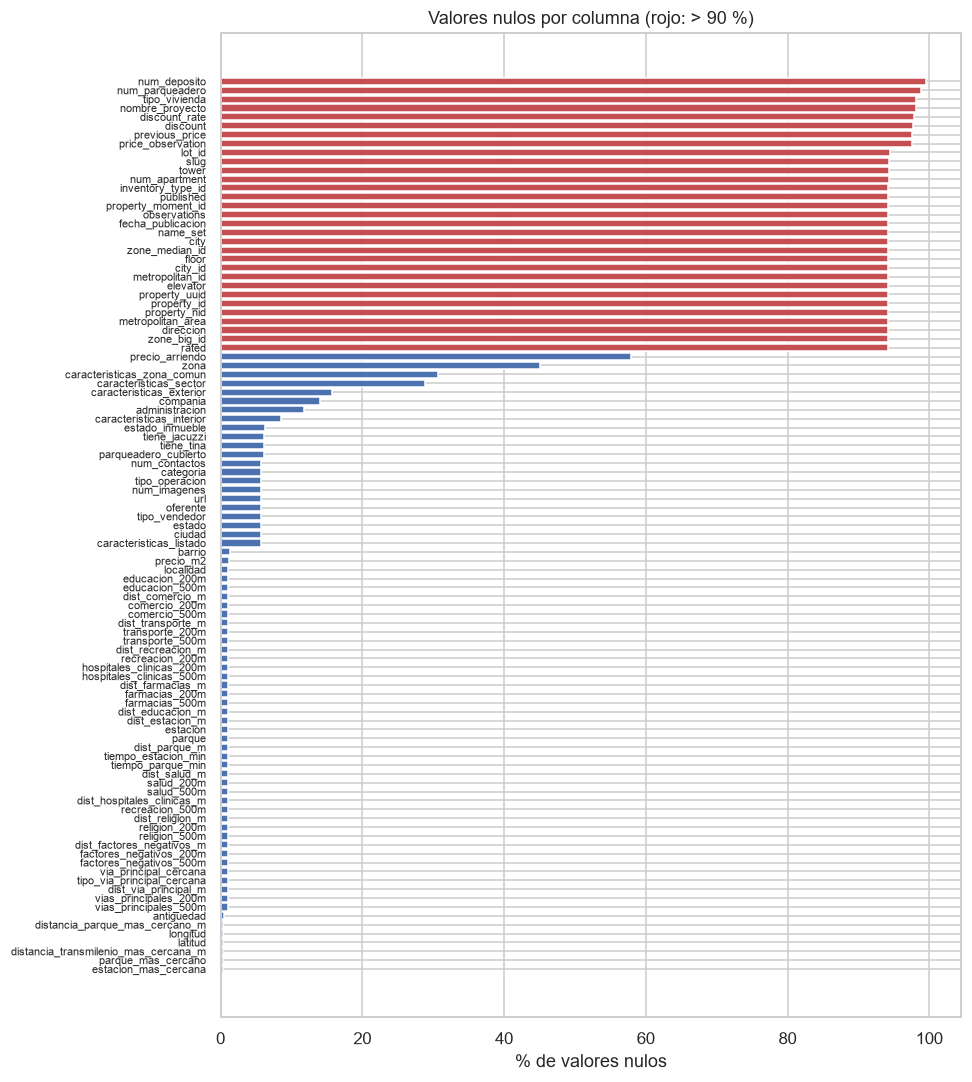

In [10]:
fig, ax = plt.subplots(figsize=(9, 10))
top = nulos[nulos > 0]
ax.barh(top.index[::-1], top.values[::-1], color=np.where(top.values[::-1] > 90, "#c44e52", "#4c72b0"))
ax.set_xlabel("% de valores nulos"); ax.set_title("Valores nulos por columna (rojo: > 90 %)")
ax.tick_params(axis="y", labelsize=7); plt.tight_layout(); plt.show()

**Lectura.** Los nulos tienen un patrón claro y *no* son aleatorios:

- Las columnas con ~94 % de nulos (`direccion`, `fecha_publicacion`, `floor`, `elevator`, `property_id`, …) **solo existen en Habi**.
- Las columnas con ~5.8 % de nulos (`url`, `estado`, `tipo_vendedor`, `tiene_jacuzzi`, …) **solo existen en Metrocuadrado**.
- Los únicos faltantes "reales" en variables de interés son `administracion` (~12 %), `antiguedad` (0.5 %) y las coordenadas (0.3 %).

**Discrepancias de tipo:** `antiguedad` es texto y mezcla años exactos (Habi) con rangos (Metrocuadrado); `tiene_jacuzzi`, `tiene_tina` y `parqueadero_cubierto` son booleanos guardados como texto; `precio_venta` y los conteos están como decimales.

### 4.2 Variable objetivo: `precio_venta`

In [11]:
df["precio_venta"].describe(percentiles=[.001, .01, .05, .25, .5, .75, .95, .99, .999]).to_frame().T

,count,mean,std,min,0.1%,1%,5%,25%,50%,75%,95%,99%,99.9%,max
precio_venta,"10,624.00","3,179,459,816.29","81,621,434,522.44","660,000.00","1,727,380.00","151,142,600.00","210,000,000.00","415,000,000.00","820,000,000.00","1,650,000,000.00","3,900,000,000.00","6,500,000,000.00","14,000,000,000.00","5,500,000,000,000.00"


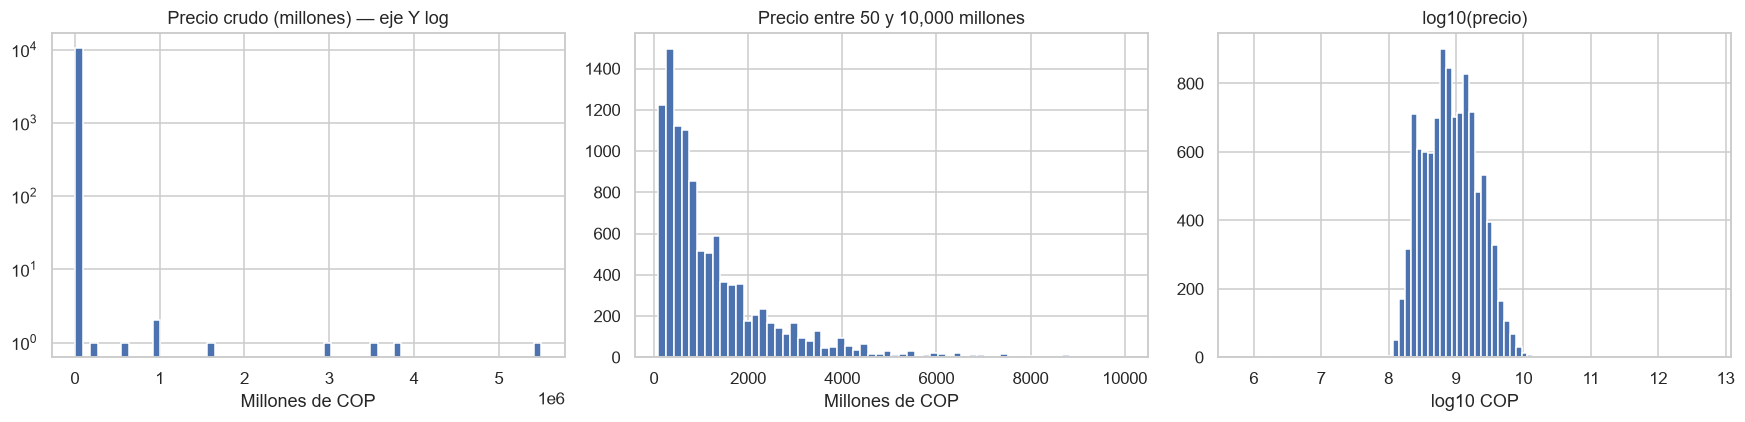

Asimetría del precio crudo: 51.4 | del log-precio en el rango plausible: 0.15
Precios < 50 millones: 19 | precios > 30,000 millones: 9


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
p = df["precio_venta"] / 1e6
axes[0].hist(p, bins=60); axes[0].set_yscale("log"); axes[0].set_title("Precio crudo (millones) — eje Y log"); axes[0].set_xlabel("Millones de COP")
axes[1].hist(p[p.between(50, 10_000)], bins=60); axes[1].set_title("Precio entre 50 y 10,000 millones"); axes[1].set_xlabel("Millones de COP")
axes[2].hist(np.log10(df["precio_venta"]), bins=80); axes[2].set_title("log10(precio)"); axes[2].set_xlabel("log10 COP")
plt.tight_layout(); plt.show()
print(f"Asimetría del precio crudo: {df['precio_venta'].skew():.1f} | del log-precio en el rango plausible: "
      f"{np.log(df.loc[df['precio_venta'].between(5e7, 3e10), 'precio_venta']).skew():.2f}")
print("Precios < 50 millones:", (df["precio_venta"] < 5e7).sum(), "| precios > 30,000 millones:", (df["precio_venta"] > 3e10).sum())

**Lectura.** El precio tiene un sesgo positivo extremo causado por **errores de digitación**: hay precios de menos de 6 millones (se escribió en miles o en millones) y de más de 100,000 millones (ceros de más). Dentro del rango plausible la distribución sigue siendo asimétrica a la derecha —pocos apartamentos de lujo muy caros—, pero su logaritmo es aproximadamente simétrico. Por eso se crea `log_precio_venta` como objetivo alternativo para la Parte 2.

### 4.3 Variables numéricas, valores atípicos e inconsistencias

In [13]:
num_clave = ["precio_venta", "area_m2", "habitaciones", "banos", "parqueaderos", "estrato", "administracion", "latitud", "longitud",
             "distancia_parque_mas_cercano_m", "distancia_transmilenio_mas_cercana_m"]
df[num_clave].describe(percentiles=[.01, .25, .5, .75, .99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
precio_venta,"10,624.00","3,179,459,816.29","81,621,434,522.44","660,000.00","151,142,600.00","415,000,000.00","820,000,000.00","1,650,000,000.00","6,500,000,000.00","5,500,000,000,000.00"
area_m2,"10,624.00",148.91,185.25,0.00,24.27,60.00,109.00,200.00,503.60,"9,237.00"
habitaciones,"10,624.00",2.75,0.86,1.00,1.00,2.00,3.00,3.00,5.00,9.00
banos,"10,624.00",2.82,1.29,0.00,1.00,2.00,3.00,4.00,5.00,5.00
parqueaderos,"10,624.00",1.70,1.24,0.00,0.00,1.00,2.00,2.00,4.00,4.00
estrato,"10,624.00",4.72,1.35,0.00,1.00,4.00,5.00,6.00,6.00,6.00
administracion,"9,378.00","5,495,553.94","95,238,859.89",0.00,0.00,"320,000.00","850,000.00","1,624,750.00","5,315,197.16","4,500,000,000.00"
latitud,"10,591.00",4.66,0.35,-0.01,4.50,4.66,4.69,4.71,4.77,6.06
longitud,"10,591.00",-73.65,5.56,-75.75,-74.20,-74.08,-74.05,-74.04,-74.02,0.00
distancia_parque_mas_cercano_m,"10,591.00","46,888.57","618,169.46",1.07,18.26,77.11,123.94,189.76,620.67,"8,236,215.01"


In [14]:
def atipicos_iqr(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

resumen_at = pd.DataFrame({"atípicos (regla IQR)": {c: atipicos_iqr(df[c].dropna()) for c in num_clave}})
resumen_at["% del total"] = resumen_at["atípicos (regla IQR)"] / len(df) * 100
display(resumen_at)

print("Inconsistencias detectadas:")
print("  área = 0 m²                     :", (df["area_m2"] == 0).sum())
print("  área < 15 m² o > 1,000 m²       :", ((df["area_m2"] < 15) | (df["area_m2"] > 1000)).sum())
print("  estrato = 0                     :", (df["estrato"] == 0).sum())
print("  baños = 0                       :", (df["banos"] == 0).sum())
print("  administración = 0              :", (df["administracion"] == 0).sum())
print("  administración > 10 millones    :", (df["administracion"] > 1e7).sum())
print("  coordenadas nulas o (0, 0)      :", (df["latitud"].isna() | (df["latitud"] == 0)).sum())
print("  inmuebles que no son apartamento:", (df["tipo_propiedad"] != "Apartamento").sum())

,atípicos (regla IQR),% del total
precio_venta,649,6.11
area_m2,321,3.02
habitaciones,196,1.84
banos,0,0.00
parqueaderos,1176,11.07
estrato,3,0.03
administracion,381,3.59
latitud,252,2.37
longitud,1051,9.89
distancia_parque_mas_cercano_m,354,3.33


Inconsistencias detectadas:
  área = 0 m²                     : 8
  área < 15 m² o > 1,000 m²       : 32
  estrato = 0                     : 3
  baños = 0                       : 4
  administración = 0              : 197
  administración > 10 millones    : 37
  coordenadas nulas o (0, 0)      : 92
  inmuebles que no son apartamento: 39


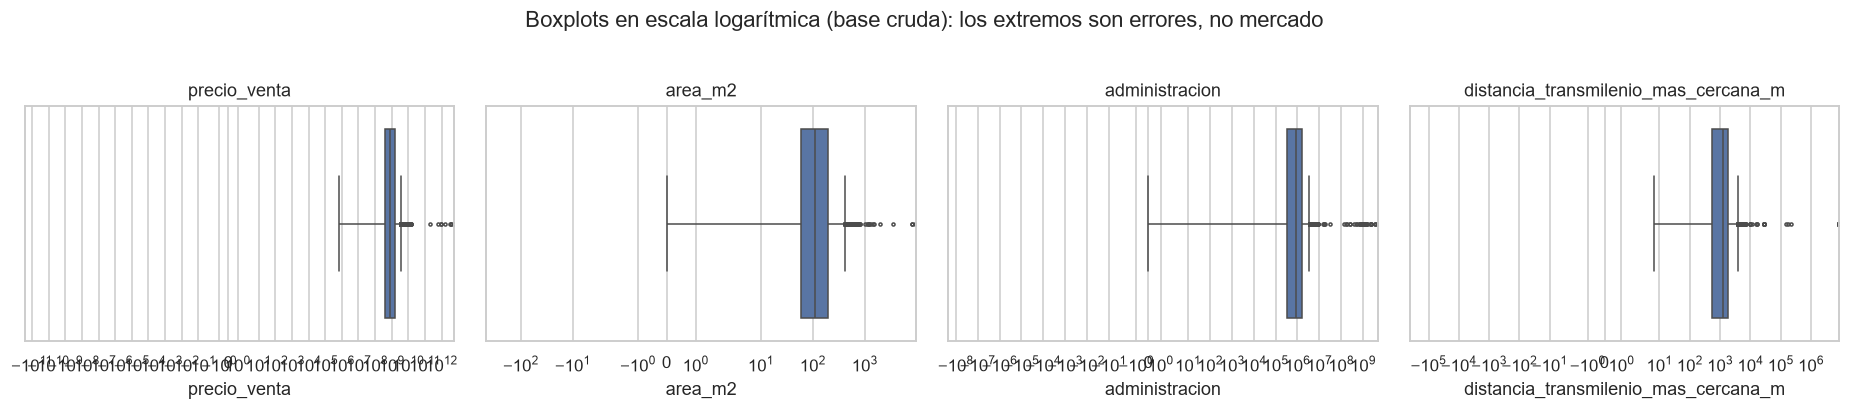

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, c in zip(axes, ["precio_venta", "area_m2", "administracion", "distancia_transmilenio_mas_cercana_m"]):
    sns.boxplot(x=df[c], ax=ax, fliersize=2); ax.set_xscale("symlog"); ax.set_title(c)
plt.suptitle("Boxplots en escala logarítmica (base cruda): los extremos son errores, no mercado", y=1.03); plt.tight_layout(); plt.show()

**Lectura.** La regla IQR marca como atípico cerca del 6 % de los precios, pero la mayoría son apartamentos de lujo reales (Rosales, Chicó, La Cabrera). Eliminar por IQR borraría justo el segmento alto del mercado. La estrategia es otra: **eliminar solo lo imposible** (errores de digitación) con reglas de negocio —rangos de precio, área y precio por m²— y **conservar los extremos legítimos**, cuyo efecto se controla con la transformación logarítmica.

## 5 · Preparación de los datos — depuración
Cada regla se aplica en orden y queda registrada en una bitácora con los registros que elimina.

In [16]:
bitacora = []
def aplicar(datos, mascara, regla):
    # Conserva las filas donde `mascara` es True y registra cuántas se eliminan.
    antes = len(datos); datos = datos[mascara].copy()
    bitacora.append({"regla": regla, "eliminados": antes - len(datos), "quedan": len(datos)})
    print(f"{regla:<74} -{antes - len(datos):>4}  -> {len(datos):,}")
    return datos

d = df.drop(columns="_union").copy()
bitacora.append({"regla": "Base del taller + variables OSM (inicio)", "eliminados": 0, "quedan": len(d)})

# 1. Solo apartamentos (Habi trae 39 casas)
d = aplicar(d, d["tipo_propiedad"] == "Apartamento", "1. Solo apartamentos (se excluyen casas)")

# 2. Coordenadas válidas dentro de Bogotá urbana
en_bogota = d["latitud"].between(4.45, 4.84) & d["longitud"].between(-74.23, -73.99)
d = aplicar(d, en_bogota, "2. Coordenadas válidas dentro de Bogotá (lat 4.45–4.84, lon -74.23 a -73.99)")

# 3. Localidad conocida
d = aplicar(d, d["localidad"].notna(), "3. Localidad no nula")

# 4. Duplicados: mismo inmueble publicado más de una vez
dup = d.duplicated(["precio_venta", "area_m2", "habitaciones", "banos", "latitud", "longitud", "descripcion"], keep="first")
d = aplicar(d, ~dup, "4. Sin duplicados (mismo precio, área, hab., baños, coordenadas y descripción)")

# 5. Precio plausible
d = aplicar(d, d["precio_venta"].between(70e6, 30_000e6), "5. Precio entre 70 y 30,000 millones")

# 6. Área plausible
d = aplicar(d, d["area_m2"].between(15, 1000), "6. Área entre 15 y 1,000 m²")

# 7. Coherencia precio/área
d["precio_m2"] = d["precio_venta"] / d["area_m2"]            # se recalcula sobre datos válidos
d = aplicar(d, d["precio_m2"].between(1.5e6, 40e6), "7. Precio por m² entre 1.5 y 40 millones")

# 8. Estrato y baños válidos
d = aplicar(d, d["estrato"].between(1, 6), "8. Estrato entre 1 y 6")
d = aplicar(d, d["banos"] >= 1, "9. Al menos un baño")

pd.DataFrame(bitacora)

1. Solo apartamentos (se excluyen casas)                                   -  39  -> 10,585
2. Coordenadas válidas dentro de Bogotá (lat 4.45–4.84, lon -74.23 a -73.99) - 116  -> 10,469
3. Localidad no nula                                                       -   4  -> 10,465
4. Sin duplicados (mismo precio, área, hab., baños, coordenadas y descripción) - 167  -> 10,298
5. Precio entre 70 y 30,000 millones                                       -  28  -> 10,270
6. Área entre 15 y 1,000 m²                                                -  30  -> 10,240
7. Precio por m² entre 1.5 y 40 millones                                   -   9  -> 10,231
8. Estrato entre 1 y 6                                                     -   3  -> 10,228
9. Al menos un baño                                                        -   4  -> 10,224


,regla,eliminados,quedan
0,Base del taller + variables OSM (inicio),0,10624
1,1. Solo apartamentos (se excluyen casas),39,10585
2,2. Coordenadas válidas dentro de Bogotá (lat 4...,116,10469
3,3. Localidad no nula,4,10465
4,"4. Sin duplicados (mismo precio, área, hab., b...",167,10298
5,"5. Precio entre 70 y 30,000 millones",28,10270
6,"6. Área entre 15 y 1,000 m²",30,10240
7,7. Precio por m² entre 1.5 y 40 millones,9,10231
8,8. Estrato entre 1 y 6,3,10228
9,9. Al menos un baño,4,10224


**Justificación de los umbrales**

- **Coordenadas:** el recuadro cubre el área urbana de Bogotá; deja fuera `(0, 0)`, registros sin ubicación y anuncios de otros municipios (Sopó, Pereira…) publicados como "Bogotá".
- **Precio 70–30,000 millones:** por debajo de 70 M no hay apartamentos en venta en Bogotá (son precios digitados en miles/millones o arriendos); por encima de 30,000 M son ceros de más. El apartamento más caro que queda en la base depurada vale 14,000 M.
- **Área 15–1,000 m²:** elimina áreas en 0, de un dígito y de miles de m² (errores), y conserva apartaestudios y penthouses.
- **Precio/m² 1.5–40 millones:** captura errores que pasan los filtros individuales (p. ej. 1,117 m² por 1,490 M). El rango es deliberadamente amplio frente al p1–p99 observado (≈ 3.3–20.6 M/m²).
- **Duplicados:** se exige coincidencia también en la descripción para no eliminar unidades distintas de un mismo proyecto nuevo.

### 5.1 Armonización de `antiguedad`
Habi reporta años exactos y Metrocuadrado rangos. Convertir rangos a un número exige inventar un valor ("Más de 20 años" ¿son 25, 40?), y esa categoría es la más frecuente. Se hace lo contrario: **los años de Habi se llevan a los rangos de Metrocuadrado**, que es la escala común más fina que ambas fuentes soportan sin inventar información.

In [17]:
def armonizar_antiguedad(v):
    if pd.isna(v):
        return "Sin información"
    v = str(v).strip()
    try:
        a = float(v)                                   # Habi: años exactos
        return ("Entre 0 y 5 años" if a <= 5 else "Entre 5 y 10 años" if a <= 10
                else "Entre 10 y 20 años" if a <= 20 else "Más de 20 años")
    except ValueError:
        if v in ("Sobre planos", "En Construcción", "Para Estrenar"):
            return "A estrenar"                        # aún no habitado
        return v                                       # rangos de Metrocuadrado y 'Remodelado'

d["antiguedad_rango"] = d["antiguedad"].map(armonizar_antiguedad)
pd.crosstab(d["antiguedad_rango"], d["fuente"], margins=True)

fuente,habi.co,metrocuadrado.com,All
antiguedad_rango,,,
A estrenar,0,200,200
Entre 0 y 5 años,201,1671,1872
Entre 10 y 20 años,163,2154,2317
Entre 5 y 10 años,91,1286,1377
Más de 20 años,116,3672,3788
Remodelado,0,621,621
Sin información,0,49,49
All,571,9653,10224


- `Sobre planos`, `En Construcción` y `Para Estrenar` se agrupan en **A estrenar** (inmueble sin uso; por separado son categorías muy pequeñas).
- `Remodelado` no es una edad sino un estado; se deja como categoría propia en lugar de forzarla a un rango.
- Los 51 nulos pasan a **Sin información** (0.5 %): se prefiere una categoría explícita a imputar la moda.

### 5.2 Variables que existen solo en una fuente
En vez de dejar nulos estructurales, se completa con lo que se sabe del negocio o con el texto del anuncio:

- `tipo_vendedor`: los registros de Habi se marcan como **iBuyer** (Habi es dueño y vendedor).
- `estado`: Habi revende apartamentos usados → **Usado**.
- `tiene_jacuzzi`, `tiene_tina`, `parqueadero_cubierto`: para Habi se extraen de la descripción del anuncio.

Además, del texto libre (descripción y características) se derivan comodidades para **ambas** fuentes con el mismo criterio.

In [18]:
def normalizar(s):
    s = unicodedata.normalize("NFKD", str(s).lower())
    return "".join(ch for ch in s if not unicodedata.combining(ch))

cols_texto = ["descripcion", "caracteristicas_interior", "caracteristicas_exterior", "caracteristicas_zona_comun"]
texto = d[cols_texto].fillna("").agg(" ; ".join, axis=1).map(normalizar)

def contiene(patron):
    return texto.str.contains(patron, regex=True)

def a_bool(col):
    return d[col].map({True: True, False: False, "True": True, "False": False})

# Variables de Metrocuadrado: se respeta el dato original y solo se completa lo faltante (Habi) desde el texto
d["tiene_jacuzzi"] = a_bool("tiene_jacuzzi").fillna(contiene(r"jacuzzi")).astype(int)
d["tiene_tina"] = a_bool("tiene_tina").fillna(contiene(r"\btina\b")).astype(int)
cubierto = a_bool("parqueadero_cubierto").fillna(contiene(r"parqueadero[^.;]{0,30}cubierto"))
d["parqueadero_cubierto"] = (cubierto & (d["parqueaderos"] > 0)).astype(int)

# Comodidades derivadas del texto para ambas fuentes
d["tiene_ascensor"] = (contiene(r"ascensor") | (d["elevator"].fillna(0) > 0)).astype(int)
d["tiene_gimnasio"] = contiene(r"(?<!cerca a )gimnasio").astype(int)
d["tiene_piscina"] = contiene(r"piscina").astype(int)
d["conjunto_cerrado"] = contiene(r"conjunto cerrado|el conjunto cuenta").astype(int)   # Habi escribe "El conjunto cuenta con..."
d["tiene_vigilancia"] = contiene(r"vigilancia|porteria|celadur").astype(int)
d["tiene_chimenea"] = contiene(r"chimenea").astype(int)
d["tiene_balcon_terraza"] = contiene(r"balcon|terraza").astype(int)
d["tiene_deposito"] = contiene(r"deposito").astype(int)

d["tipo_vendedor"] = d["tipo_vendedor"].fillna("iBuyer")
d["estado"] = d["estado"].fillna("Usado")

BINARIAS = ["tiene_jacuzzi", "tiene_tina", "parqueadero_cubierto", "tiene_ascensor", "tiene_gimnasio", "tiene_piscina",
            "conjunto_cerrado", "tiene_vigilancia", "tiene_chimenea", "tiene_balcon_terraza", "tiene_deposito"]
(d.groupby("fuente")[BINARIAS].mean() * 100).T.rename_axis("% con la comodidad")

fuente,habi.co,metrocuadrado.com
% con la comodidad,,
tiene_jacuzzi,0.18,5.50
tiene_tina,0.00,18.45
parqueadero_cubierto,7.88,34.06
tiene_ascensor,58.67,73.52
tiene_gimnasio,14.71,43.43
tiene_piscina,3.68,15.14
conjunto_cerrado,71.80,50.64
tiene_vigilancia,80.56,74.44
tiene_chimenea,0.00,40.81


**Advertencia sobre las comodidades derivadas del texto.** Las descripciones de Habi son cortas y siguen una plantilla, mientras que Metrocuadrado trae listas detalladas de características. Por eso las comodidades aparecen mucho menos en Habi (chimenea, tina, balcón, depósito): parte de esa diferencia es real —son apartamentos más económicos— y parte es simplemente que Habi no lo menciona. Un 0 en Habi significa "no se menciona", no necesariamente "no tiene". Es otra razón para mantener `tipo_vendedor` como control en el modelo.

### 5.3 Selección de variables
Criterios para descartar una columna: (a) más de 90 % de nulos por ser exclusiva de Habi; (b) identificadores o texto libre; (c) constantes; (d) metadatos del anuncio que no describen el inmueble; (e) **fuga de información** (se calculan a partir del precio).

In [19]:
descartar = {
    "Exclusivas de Habi (≈94 % nulos, hueco estructural)": ["direccion", "fecha_publicacion", "published", "inventory_type_id",
        "property_moment_id", "slug", "name_set", "observations", "property_id", "property_uuid", "num_apartment", "elevator",
        "floor", "lot_id", "zone_median_id", "zone_big_id", "city_id", "city", "metropolitan_area", "metropolitan_id",
        "property_nid", "num_parqueadero", "num_deposito", "tower", "rated"],
    "Fuga de información (derivadas del precio)": ["price_observation", "previous_price", "discount", "discount_rate"],
    "Constantes o redundantes": ["tipo_propiedad", "website", "fecha_descarga", "categoria", "ciudad", "tipo_operacion",
        "oferente", "estado_inmueble", "zona"],
    "Texto libre / identificadores (ya aprovechados en 5.2)": ["titulo", "descripcion", "url", "caracteristicas_listado",
        "caracteristicas_interior", "caracteristicas_exterior", "caracteristicas_zona_comun", "caracteristicas_sector",
        "compania", "nombre_proyecto"],
    "Metadatos del anuncio o > 55 % nulos": ["num_imagenes", "num_contactos", "precio_arriendo", "tipo_vivienda"],
    "Reemplazada por antiguedad_rango": ["antiguedad"],
}
for motivo, cols in descartar.items():
    print(f"- {motivo}: {len(cols)} columnas")
d = d.drop(columns=[c for cols in descartar.values() for c in cols])
print("\nColumnas que quedan:", d.shape[1])

- Exclusivas de Habi (≈94 % nulos, hueco estructural): 25 columnas
- Fuga de información (derivadas del precio): 4 columnas
- Constantes o redundantes: 9 columnas
- Texto libre / identificadores (ya aprovechados en 5.2): 10 columnas
- Metadatos del anuncio o > 55 % nulos: 4 columnas
- Reemplazada por antiguedad_rango: 1 columnas

Columnas que quedan: 70


### 5.4 División entrenamiento / prueba (80/20)
La división se hace **antes** de imputar y escalar, para que las medianas, medias y desviaciones se aprendan solo con entrenamiento y no haya fuga de información hacia prueba. Se estratifica por localidad para que las localidades pequeñas queden representadas en ambos conjuntos.

In [20]:
d = d.reset_index(drop=True)
idx_train, idx_test = train_test_split(d.index, test_size=0.20, random_state=SEMILLA, stratify=d["localidad"])
d["conjunto"] = "train"; d.loc[idx_test, "conjunto"] = "test"
es_train = d["conjunto"] == "train"
print(d["conjunto"].value_counts().to_string())
print(f"\nPrecio mediano — train: {d.loc[es_train, 'precio_venta'].median():,.0f} | test: {d.loc[~es_train, 'precio_venta'].median():,.0f}")

conjunto
train    8179
test     2045

Precio mediano — train: 830,000,000 | test: 828,000,000


### 5.5 Tratamiento de nulos: `administracion`
Es la única variable de interés con faltantes relevantes. Antes de imputar se invalidan los valores imposibles: cuota en 0, o cuota por m² fuera de 500–40,000 COP/m² (cuotas de pocos miles de pesos o de cientos de millones son errores de digitación).

**¿Eliminar o imputar?** Eliminar descartaría ~14 % de la base por una sola variable. Se imputa con la **mediana de la cuota por m² según estrato** (calculada en entrenamiento) multiplicada por el área del apartamento: respeta que la administración crece con el tamaño y con el nivel del edificio, y la mediana es robusta a extremos. Se agrega la bandera `administracion_imputada` para que el modelo pueda distinguir los valores estimados.

In [21]:
adm_m2 = d["administracion"] / d["area_m2"]
invalida = d["administracion"].notna() & ((d["administracion"] <= 0) | ~adm_m2.between(500, 40_000))
print(f"Nulos originales: {d['administracion'].isna().sum():,} | valores inválidos convertidos a nulo: {invalida.sum():,}")
d.loc[invalida, "administracion"] = np.nan
d["administracion_imputada"] = d["administracion"].isna().astype(int)

adm_m2 = d["administracion"] / d["area_m2"]
mediana_estrato = adm_m2[es_train].groupby(d.loc[es_train, "estrato"]).median()      # aprendida solo con train
print("\nMediana de administración por m² según estrato (train):\n", mediana_estrato.round(0).to_string())

falta = d["administracion"].isna()
d.loc[falta, "administracion"] = (d.loc[falta, "estrato"].map(mediana_estrato) * d.loc[falta, "area_m2"]).round(-2)
print(f"\nImputados: {falta.sum():,} ({falta.mean():.1%}) | nulos restantes en administracion: {d['administracion'].isna().sum()}")

Nulos originales: 1,199 | valores inválidos convertidos a nulo: 250

Mediana de administración por m² según estrato (train):
 estrato
1   3,583.00
2   2,396.00
3   3,958.00
4   5,887.00
5   6,981.00
6   8,463.00

Imputados: 1,449 (14.2%) | nulos restantes en administracion: 0


In [22]:
# Conversión de tipos y objetivo en logaritmo
for c in ["habitaciones", "banos", "parqueaderos", "estrato"]:
    d[c] = d[c].astype(int)
d["log_precio_venta"] = np.log(d["precio_venta"])
d["localidad"] = d["localidad"].str.strip().str.upper()
d["barrio"] = d["barrio"].fillna("SIN INFORMACION").str.strip().str.upper()

restantes = d.isna().sum()
print("Nulos restantes en la base depurada:", int(restantes.sum()))
assert restantes.sum() == 0, restantes[restantes > 0]

Nulos restantes en la base depurada: 0


## 6 · EDA sobre la base depurada
Con los errores fuera, las relaciones ya son interpretables.

In [23]:
print(f"Base depurada: {len(d):,} registros × {d.shape[1]} columnas")
d[["precio_venta", "area_m2", "precio_m2", "administracion", "habitaciones", "banos", "parqueaderos", "estrato",
   "distancia_parque_mas_cercano_m", "distancia_transmilenio_mas_cercana_m"]].describe().T

Base depurada: 10,224 registros × 73 columnas


,count,mean,std,min,25%,50%,75%,max
precio_venta,"10,224.00","1,282,412,610.22","1,316,187,494.68","91,445,000.00","420,000,000.00","830,000,000.00","1,650,000,000.00","14,000,000,000.00"
area_m2,"10,224.00",145.61,110.88,15.00,60.00,110.00,200.00,800.00
precio_m2,"10,224.00","8,196,435.12","3,260,607.02","1,590,476.19","5,955,124.28","7,547,169.81","9,638,915.66","27,801,679.10"
administracion,"10,224.00","1,106,250.78","1,039,254.98","30,000.00","320,000.00","798,000.00","1,586,350.00","9,000,000.00"
habitaciones,"10,224.00",2.75,0.85,1.00,2.00,3.00,3.00,5.00
banos,"10,224.00",2.82,1.29,1.00,2.00,3.00,4.00,5.00
parqueaderos,"10,224.00",1.71,1.24,0.00,1.00,2.00,2.00,4.00
estrato,"10,224.00",4.73,1.34,1.00,4.00,5.00,6.00,6.00
distancia_parque_mas_cercano_m,"10,224.00",142.95,95.52,1.07,77.05,123.30,187.83,"1,716.59"
distancia_transmilenio_mas_cercana_m,"10,224.00","1,343.43",961.62,6.35,554.19,"1,226.32","1,814.01","7,269.08"


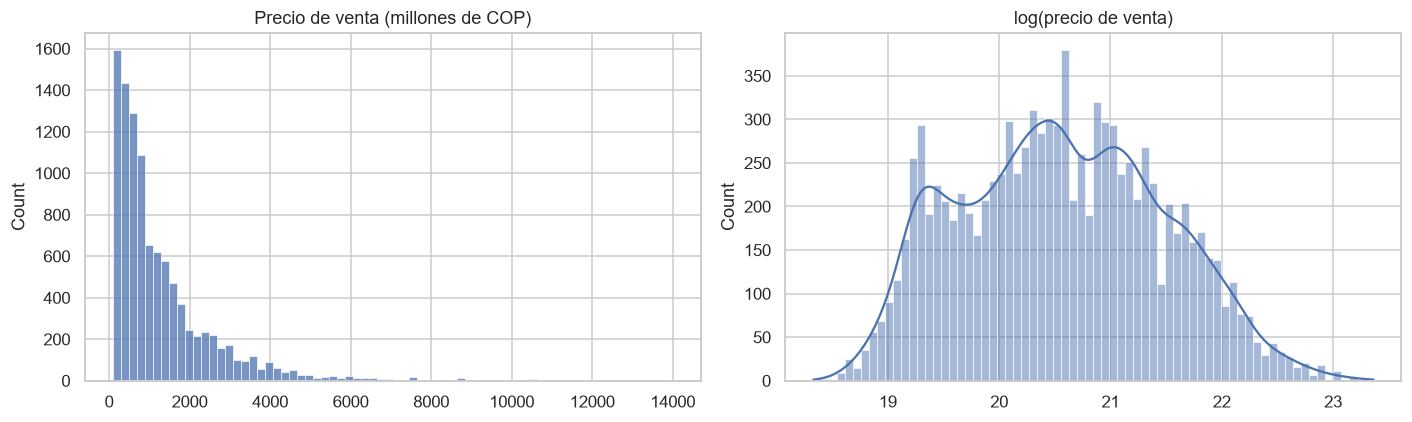

Asimetría — precio: 2.64 | log-precio: 0.14


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(d["precio_venta"] / 1e6, bins=70, ax=axes[0]); axes[0].set_title("Precio de venta (millones de COP)"); axes[0].set_xlabel("")
sns.histplot(d["log_precio_venta"], bins=70, kde=True, ax=axes[1]); axes[1].set_title("log(precio de venta)"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()
print(f"Asimetría — precio: {d['precio_venta'].skew():.2f} | log-precio: {d['log_precio_venta'].skew():.2f}")

### 6.1 Precio según localidad y estrato

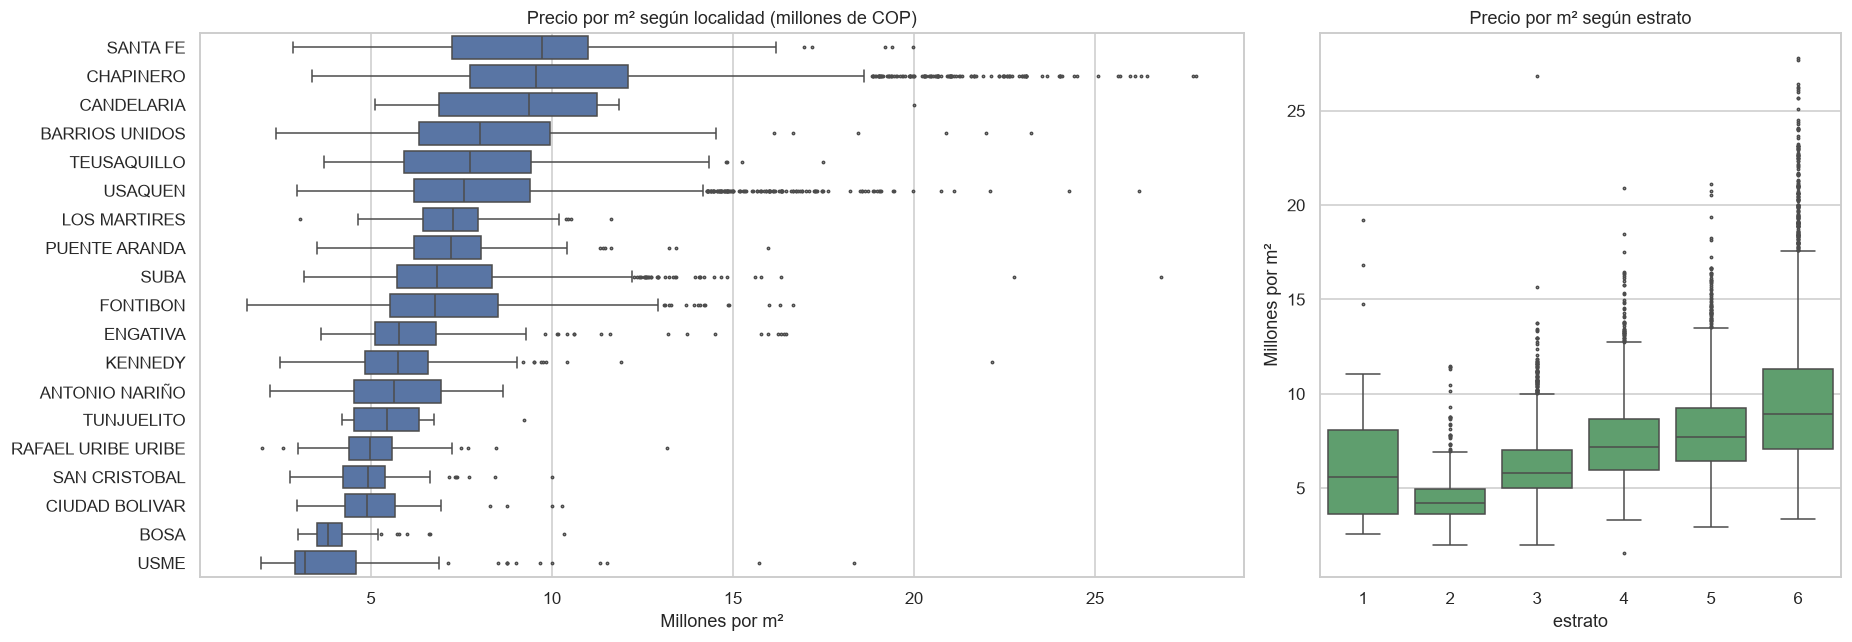

,n,precio_mediano_M,precio_m2_mediano_M,area_mediana,estrato_mediano
localidad,,,,,
SANTA FE,176,510.00,9.74,58.70,4.00
CHAPINERO,2577,"1,800.00",9.56,204.00,6.00
CANDELARIA,32,550.00,9.37,62.15,3.00
BARRIOS UNIDOS,192,592.50,8.03,75.00,4.00
TEUSAQUILLO,287,670.00,7.75,97.00,4.00
USAQUEN,3326,951.00,7.56,132.00,6.00
LOS MARTIRES,140,274.65,7.26,37.00,3.00
PUENTE ARANDA,140,295.00,7.21,41.80,3.00
SUBA,1597,736.30,6.84,103.91,5.00


Kruskal-Wallis del precio por m² entre localidades: H = 2,817, p = 0.00e+00
Precio por m² mediano según estrato (millones): {1: 5.57, 2: 4.19, 3: 5.8, 4: 7.18, 5: 7.71, 6: 8.92} | registros: {1: 118, 2: 464, 3: 1665, 4: 1987, 5: 1588, 6: 4402}


In [25]:
orden = d.groupby("localidad")["precio_m2"].median().sort_values(ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [2, 1]})
sns.boxplot(data=d, y="localidad", x=d["precio_m2"] / 1e6, order=orden, ax=axes[0], fliersize=1.5, color="#4c72b0")
axes[0].set_title("Precio por m² según localidad (millones de COP)"); axes[0].set_xlabel("Millones por m²"); axes[0].set_ylabel("")
sns.boxplot(data=d, x="estrato", y=d["precio_m2"] / 1e6, ax=axes[1], fliersize=1.5, color="#55a868")
axes[1].set_title("Precio por m² según estrato"); axes[1].set_ylabel("Millones por m²")
plt.tight_layout(); plt.show()

resumen_loc = d.groupby("localidad").agg(n=("id", "size"), precio_mediano_M=("precio_venta", lambda s: s.median() / 1e6),
                                         precio_m2_mediano_M=("precio_m2", lambda s: s.median() / 1e6),
                                         area_mediana=("area_m2", "median"), estrato_mediano=("estrato", "median")).loc[orden]
display(resumen_loc)
h, pval = stats.kruskal(*[g["precio_m2"].values for _, g in d.groupby("localidad")])
print(f"Kruskal-Wallis del precio por m² entre localidades: H = {h:,.0f}, p = {pval:.2e}")
print("Precio por m² mediano según estrato (millones):", (d.groupby("estrato")["precio_m2"].median() / 1e6).round(2).to_dict(),
      "| registros:", d["estrato"].value_counts().sort_index().to_dict())

**Lectura.** Las diferencias entre localidades son grandes y estadísticamente significativas (Kruskal-Wallis, p ≈ 0).

- En **precio total** domina Chapinero (mediana de 1,800 M, apartamentos de ~200 m² y estrato 6), seguida de Usaquén.
- En **precio por m²** Santa Fe y La Candelaria quedan a la altura de Chapinero (≈ 9.4–9.7 M/m²) pese a ser estrato 3–4: allí se venden apartamentos pequeños del centro, y el m² de un apartaestudio es más caro que el de un apartamento grande. Precio total y precio por m² cuentan historias distintas, y el área interactúa con la ubicación.
- Bosa y Usme están en el otro extremo (≈ 3.2–3.8 M/m²), menos de la mitad que el centro y el norte.
- El precio por m² sube con el estrato de 2 a 6. El estrato 1 rompe el patrón (m² más caro que en estrato 2), pero son pocos registros, así que ese dato hay que leerlo con cautela.

Localidad y estrato son predictores obligados.

### 6.2 Relación del precio con las variables numéricas

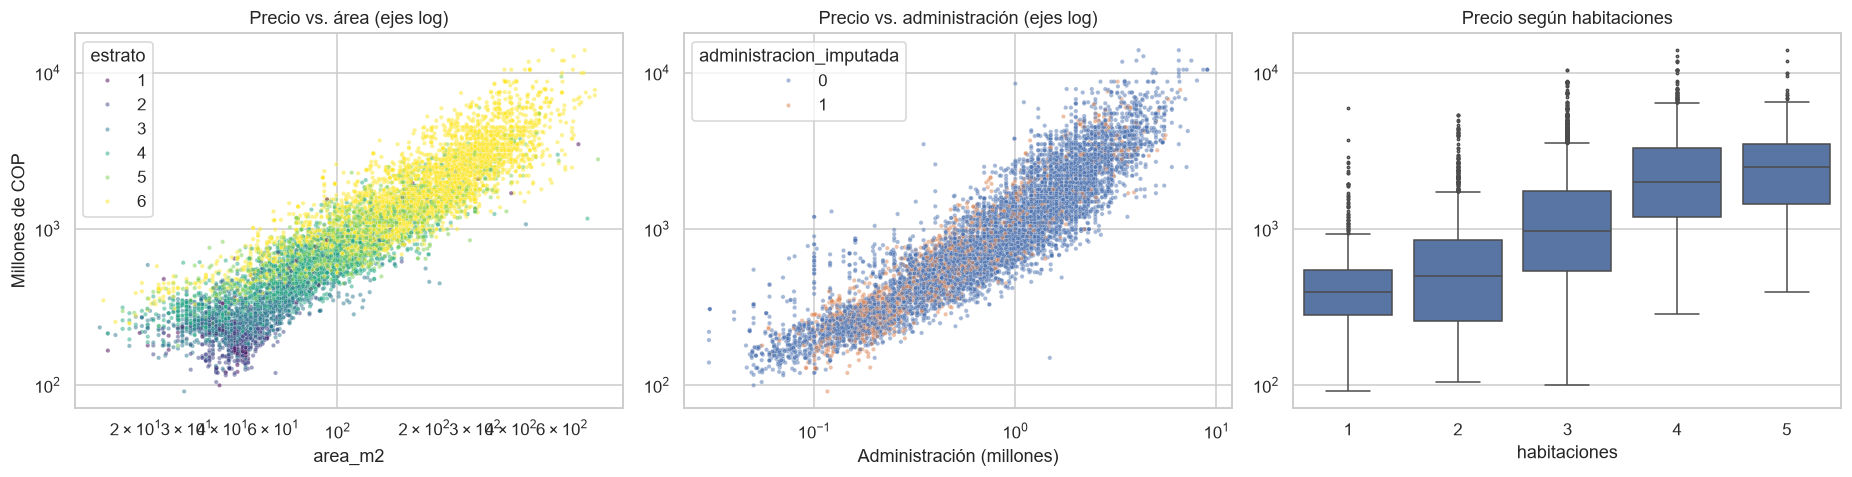

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=d, x="area_m2", y=d["precio_venta"] / 1e6, hue="estrato", palette="viridis", s=8, alpha=.5, ax=axes[0])
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_title("Precio vs. área (ejes log)"); axes[0].set_ylabel("Millones de COP")
sns.scatterplot(data=d, x=d["administracion"] / 1e6, y=d["precio_venta"] / 1e6, hue="administracion_imputada", s=8, alpha=.5, ax=axes[1])
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_title("Precio vs. administración (ejes log)")
axes[1].set_xlabel("Administración (millones)"); axes[1].set_ylabel("")
sns.boxplot(data=d, x="habitaciones", y=d["precio_venta"] / 1e6, ax=axes[2], fliersize=1.5, color="#4c72b0")
axes[2].set_yscale("log"); axes[2].set_title("Precio según habitaciones"); axes[2].set_ylabel("")
plt.tight_layout(); plt.show()

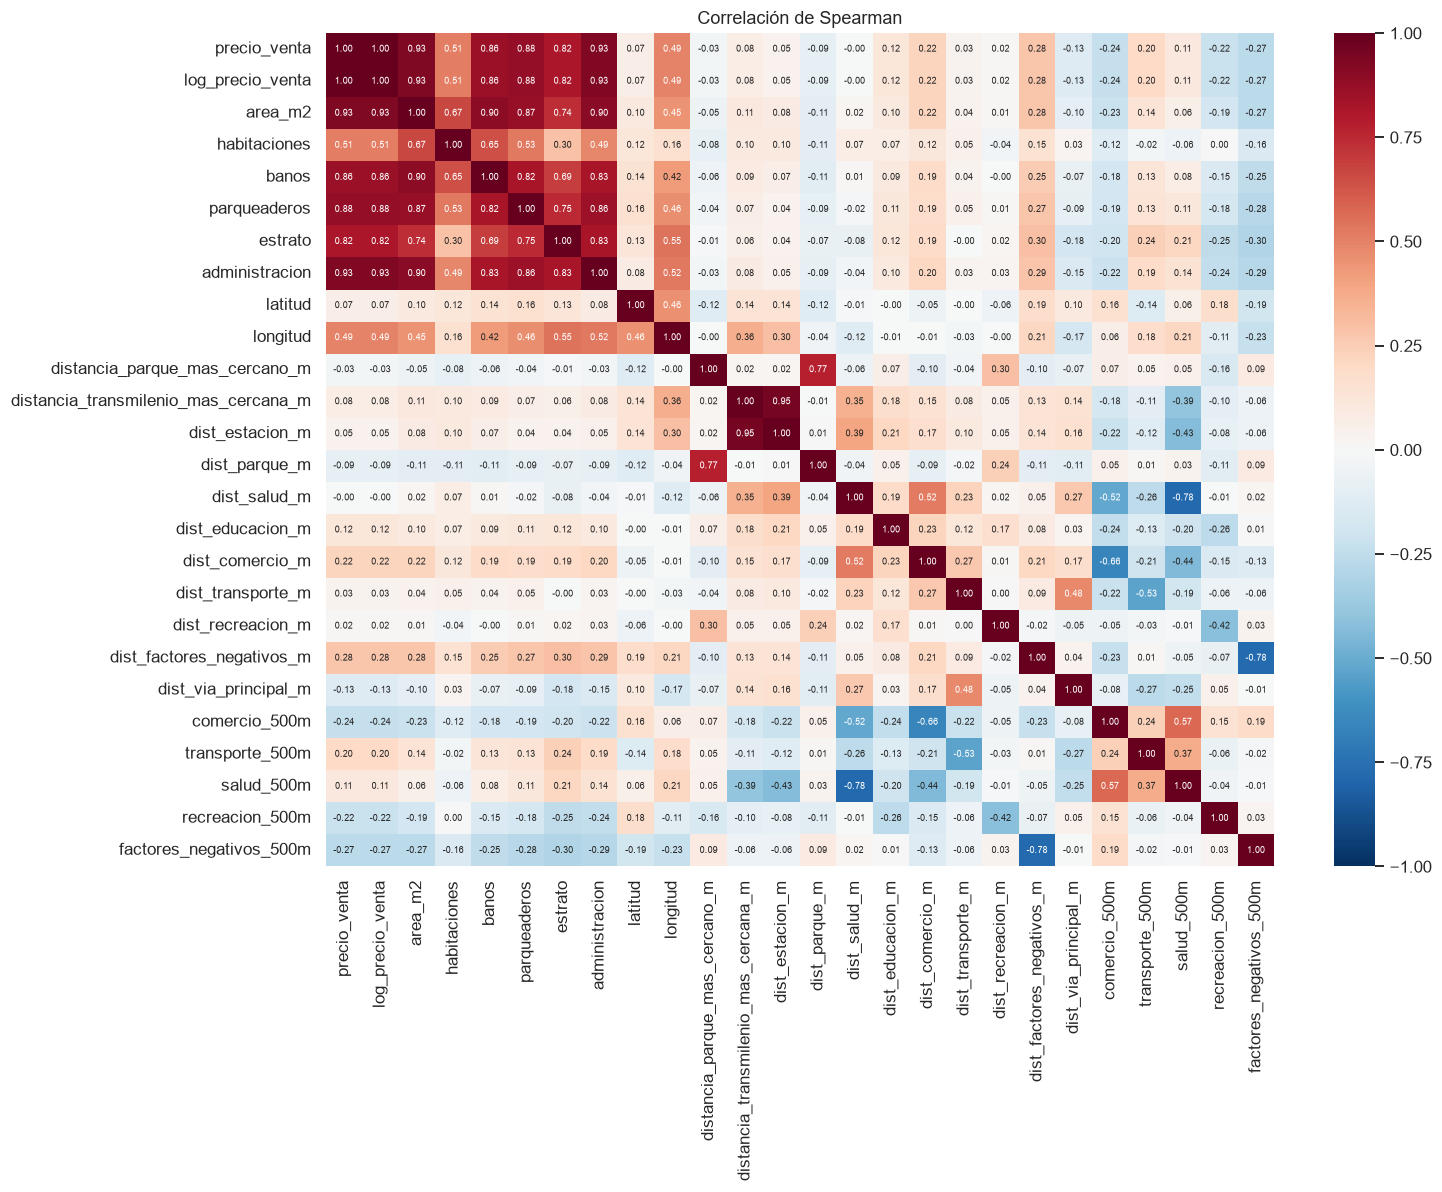

,Spearman con precio_venta
area_m2,0.93
administracion,0.93
parqueaderos,0.88
banos,0.86
estrato,0.82
tiene_chimenea,0.56
habitaciones,0.51
longitud,0.49
tiene_balcon_terraza,0.41
tiene_deposito,0.34


In [27]:
num_eda = ["precio_venta", "log_precio_venta", "area_m2", "habitaciones", "banos", "parqueaderos", "estrato", "administracion",
           "latitud", "longitud", "distancia_parque_mas_cercano_m", "distancia_transmilenio_mas_cercana_m",
           "dist_estacion_m", "dist_parque_m", "dist_salud_m", "dist_educacion_m", "dist_comercio_m", "dist_transporte_m",
           "dist_recreacion_m", "dist_factores_negativos_m", "dist_via_principal_m", "comercio_500m", "transporte_500m",
           "salud_500m", "recreacion_500m", "factores_negativos_500m"]
corr = d[num_eda].corr(method="spearman")
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 6}, ax=ax)
ax.set_title("Correlación de Spearman"); plt.tight_layout(); plt.show()

todas_num = d.select_dtypes("number").drop(columns=["precio_venta", "log_precio_venta", "precio_m2"]).columns
corr_precio = d[todas_num].corrwith(d["precio_venta"], method="spearman").sort_values(key=abs, ascending=False)
corr_precio.head(20).rename("Spearman con precio_venta").to_frame()

**Lectura.** El precio se asocia con fuerza a `area_m2`, `administracion`, `banos`, `parqueaderos` y `estrato`. Hay multicolinealidad esperable entre esas mismas variables (los apartamentos grandes tienen más baños, más parqueaderos y cuota más alta), a tener en cuenta en la regresión de la Parte 2. `habitaciones` correlaciona menos que `banos`: un apartamento de lujo no necesariamente tiene más cuartos, pero sí más baños.

### 6.3 ¿Influye la distancia a parques y a TransMilenio?

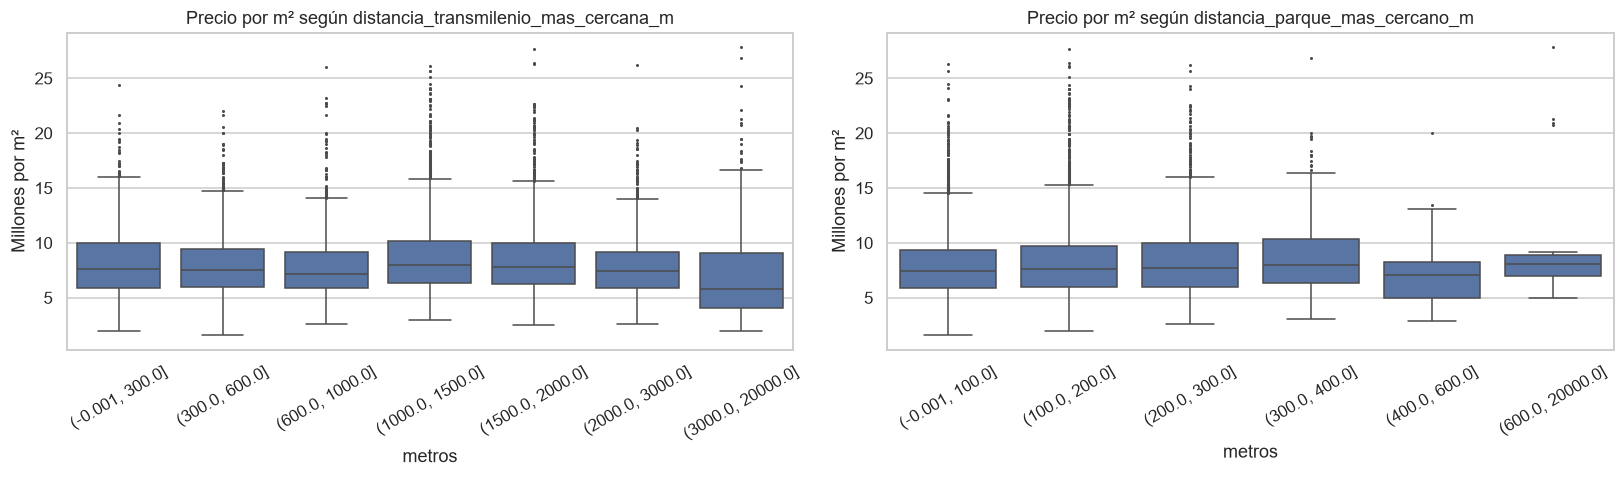

distancia_transmilenio_mas_cercana_m     Spearman con precio/m²: -0.037 (p = 2.0e-04) | mediana dentro de localidad: -0.076
distancia_parque_mas_cercano_m           Spearman con precio/m²: +0.042 (p = 1.9e-05) | mediana dentro de localidad: +0.053

Haversine vs. OSM — correlación de Pearson:
  estación: 0.963 | parque: 0.758
  dist_estacion_m vs. tiempo_estacion_min: 1.0000 | dist_parque_m vs. tiempo_parque_min: 0.9999


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, col, cortes in [(axes[0], "distancia_transmilenio_mas_cercana_m", [0, 300, 600, 1000, 1500, 2000, 3000, 20000]),
                        (axes[1], "distancia_parque_mas_cercano_m", [0, 100, 200, 300, 400, 600, 20000])]:
    tramo = pd.cut(d[col], cortes, include_lowest=True)
    sns.boxplot(x=tramo, y=d["precio_m2"] / 1e6, ax=ax, fliersize=1, color="#4c72b0")
    ax.set_title(f"Precio por m² según {col}"); ax.set_ylabel("Millones por m²"); ax.set_xlabel("metros"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

for col in ["distancia_transmilenio_mas_cercana_m", "distancia_parque_mas_cercano_m"]:
    r_tot = stats.spearmanr(d[col], d["precio_m2"])
    r_loc = d.groupby("localidad").apply(lambda g: stats.spearmanr(g[col], g["precio_m2"])[0] if len(g) > 30 else np.nan).median()
    print(f"{col:<40} Spearman con precio/m²: {r_tot[0]:+.3f} (p = {r_tot[1]:.1e}) | mediana dentro de localidad: {r_loc:+.3f}")
print("\nHaversine vs. OSM — correlación de Pearson:")
print(f"  estación: {d['distancia_transmilenio_mas_cercana_m'].corr(d['dist_estacion_m']):.3f} | parque: {d['distancia_parque_mas_cercano_m'].corr(d['dist_parque_m']):.3f}")
print(f"  dist_estacion_m vs. tiempo_estacion_min: {d['dist_estacion_m'].corr(d['tiempo_estacion_min']):.4f} | dist_parque_m vs. tiempo_parque_min: {d['dist_parque_m'].corr(d['tiempo_parque_min']):.4f}")

**Lectura.** Por sí solas, ambas distancias influyen **muy poco** en el precio por m²: las correlaciones de Spearman son significativas por el tamaño de la muestra, pero casi nulas en magnitud (|ρ| < 0.05 en toda la ciudad y < 0.1 dentro de cada localidad).

- **TransMilenio:** el precio por m² mediano se mantiene entre 7.2 y 7.9 M sin importar si la estación está a 200 m o a 3 km; solo cae con claridad (≈ 5.8 M) más allá de 3 km, que corresponde a la periferia. La explicación es de composición: zonas muy caras (Rosales, Chicó oriental, cerros de Usaquén) están lejos de las troncales, y zonas económicas las tienen cerca, así que los dos efectos se cancelan.
- **Parques:** el 75 % de los apartamentos tiene un parque a menos de 190 m. Con tan poca variación, la variable casi no discrimina.

Conclusión: las distancias no reemplazan a localidad y estrato; su posible aporte es explicar diferencias *dentro* de una misma zona, y eso se debe evaluar en el modelo de la Parte 2 con las demás variables controladas. Las dos medidas de distancia a estación (Haversine y OSM) están muy correlacionadas (0.96); las de parque menos (0.76), porque miden cosas distintas (centroide vs. borde del parque).

`tiempo_estacion_min` y `tiempo_parque_min` son una transformación lineal de las distancias OSM (correlación ≈ 1), por lo que no aportan información nueva y se excluyen de la matriz de modelado.

### 6.4 ¿Son distintas las dos fuentes?

fuente,habi.co,metrocuadrado.com
n,571.00,"9,653.00"
precio_mediano_M,240.00,880.00
precio_m2_mediano_M,5.54,7.67
area_mediana,47.00,117.00
estrato_medio,3.03,4.83
pct_jacuzzi,0.18,5.50
pct_tina,0.00,18.45


Mann-Whitney precio_venta  p = 1.07e-214
Mann-Whitney precio_m2     p = 1.11e-96
Mann-Whitney area_m2       p = 7.36e-174
Mann-Whitney estrato       p = 2.68e-189


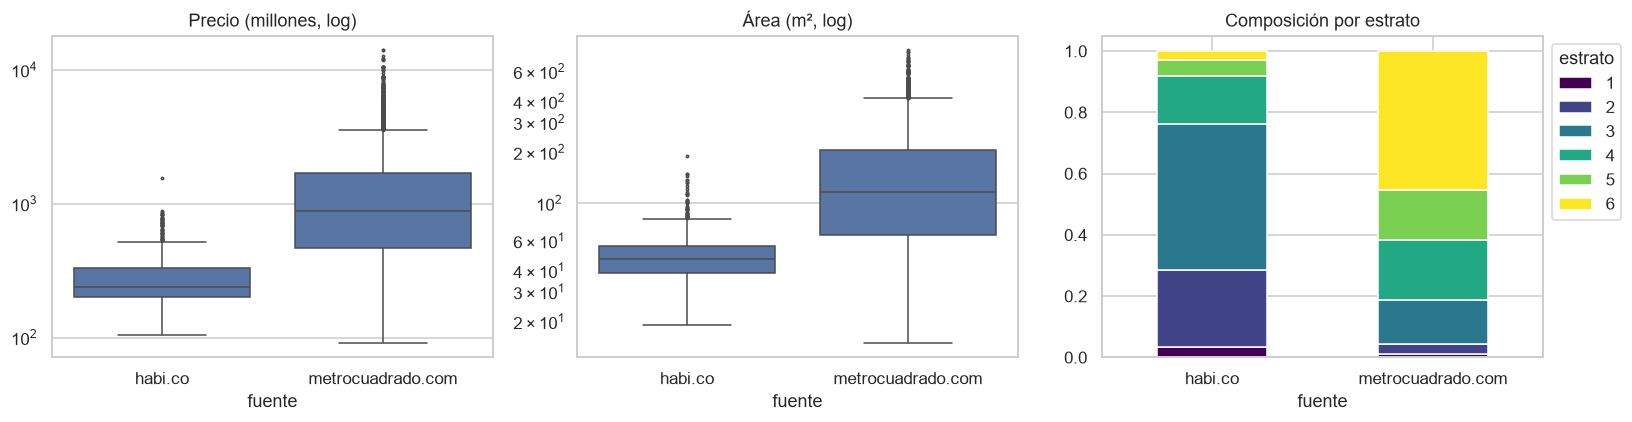

In [29]:
comp = d.groupby("fuente").agg(n=("id", "size"), precio_mediano_M=("precio_venta", lambda s: s.median() / 1e6),
                               precio_m2_mediano_M=("precio_m2", lambda s: s.median() / 1e6), area_mediana=("area_m2", "median"),
                               estrato_medio=("estrato", "mean"), pct_jacuzzi=("tiene_jacuzzi", lambda s: s.mean() * 100),
                               pct_tina=("tiene_tina", lambda s: s.mean() * 100)).T
display(comp)
habi, mc = d[d["fuente"] == "habi.co"], d[d["fuente"] == "metrocuadrado.com"]
for c in ["precio_venta", "precio_m2", "area_m2", "estrato"]:
    u, pval = stats.mannwhitneyu(habi[c], mc[c])
    print(f"Mann-Whitney {c:<13} p = {pval:.2e}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=d, x="fuente", y=d["precio_venta"] / 1e6, ax=axes[0], fliersize=1.5); axes[0].set_yscale("log"); axes[0].set_title("Precio (millones, log)"); axes[0].set_ylabel("")
sns.boxplot(data=d, x="fuente", y="area_m2", ax=axes[1], fliersize=1.5); axes[1].set_yscale("log"); axes[1].set_title("Área (m², log)"); axes[1].set_ylabel("")
pd.crosstab(d["fuente"], d["estrato"], normalize="index").plot(kind="bar", stacked=True, ax=axes[2], colormap="viridis", rot=0)
axes[2].set_title("Composición por estrato"); axes[2].legend(title="estrato", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

**Lectura.** Las fuentes son nichos distintos y la diferencia es significativa en precio, área y estrato (Mann-Whitney, p ≈ 0): Habi vende apartamentos más pequeños, más baratos y de estratos 2–4; Metrocuadrado está dominado por estratos 5–6. **Decisión:** se conservan ambas, porque Habi cubre un segmento que Metrocuadrado representa poco, pero se deja `tipo_vendedor` (que identifica a Habi como iBuyer) como variable de control. En la Parte 2 conviene revisar si los residuos del modelo difieren por fuente.

## 7 · Escalado y codificación
**Escalado.** Se usa **StandardScaler** (media 0, desviación 1) y no Min-Max: las variables tienen colas largas (área, administración, distancias) y con Min-Max unos pocos valores extremos comprimirían al resto en un intervalo mínimo. A las variables muy asimétricas se les aplica antes `log1p`. El escalador se ajusta **solo con entrenamiento**.

**Codificación.** One-Hot Encoding para las categóricas nominales de baja cardinalidad: `localidad`, `antiguedad_rango`, `tipo_vendedor`, `estado` y `tipo_via_principal_cercana`. `estrato` es ordinal y se deja numérico. `barrio`, `estacion`, `parque` y `via_principal_cercana` tienen cientos de categorías: se conservan en la base depurada como referencia, pero no se codifican.

**Excluidas de la matriz de modelado:** `precio_m2` (se calcula con el precio: fuga de información), `tiempo_*` (redundantes con las distancias), `fuente` (ya contenida en `tipo_vendedor`) e identificadores.

In [30]:
conteos_osm = [c for c in d.columns if c.endswith(("_200m", "_500m"))]
dist_osm = [c for c in d.columns if c.startswith("dist_")]
NUMERICAS = (["area_m2", "habitaciones", "banos", "parqueaderos", "estrato", "administracion", "latitud", "longitud",
              "distancia_parque_mas_cercano_m", "distancia_transmilenio_mas_cercana_m"] + dist_osm + conteos_osm)
BIN = BINARIAS + ["administracion_imputada"]
CATEGORICAS = ["localidad", "antiguedad_rango", "tipo_vendedor", "estado", "tipo_via_principal_cercana"]

X_num = d[NUMERICAS].astype(float).copy()
asimetria = X_num[es_train].skew()
con_log = asimetria[asimetria > 1].index.tolist()                 # log1p a las muy asimétricas
X_num[con_log] = np.log1p(X_num[con_log])
print(f"{len(NUMERICAS)} numéricas ({len(con_log)} con log1p), {len(BIN)} binarias, {len(CATEGORICAS)} categóricas")

escalador = StandardScaler().fit(X_num[es_train])                 # se ajusta solo con train
X_num = pd.DataFrame(escalador.transform(X_num), columns=NUMERICAS, index=d.index)

X_cat = pd.get_dummies(d[CATEGORICAS], prefix_sep="=", dtype=int)
X_cat.columns = [normalizar(c).replace(" ", "_") for c in X_cat.columns]

modelado = pd.concat([d[["id", "fuente", "conjunto"]], X_num, d[BIN], X_cat, d[["precio_venta", "log_precio_venta"]]], axis=1)
train, test = modelado[es_train].drop(columns="conjunto"), modelado[~es_train].drop(columns="conjunto")
print(f"train: {train.shape} | test: {test.shape} | nulos: {int(modelado.isna().sum().sum())}")
print("Media y desviación de las numéricas en train:", round(train[NUMERICAS].mean().abs().max(), 6), "/", round(train[NUMERICAS].std().mean(), 3))

42 numéricas (34 con log1p), 12 binarias, 5 categóricas
train: (8179, 93) | test: (2045, 93) | nulos: 0
Media y desviación de las numéricas en train: 0.0 / 1.0


## 8 · Dataset final

In [31]:
orden_cols = (["fuente", "id", "conjunto", "precio_venta", "log_precio_venta", "precio_m2",
               "area_m2", "habitaciones", "banos", "parqueaderos", "estrato", "administracion", "administracion_imputada",
               "antiguedad_rango", "estado", "tipo_vendedor", "localidad", "barrio", "latitud", "longitud"] + BINARIAS +
              ["distancia_parque_mas_cercano_m", "parque_mas_cercano", "distancia_transmilenio_mas_cercana_m", "estacion_mas_cercana"])
orden_cols += [c for c in d.columns if c not in orden_cols]       # variables OSM al final
base = d[orden_cols].copy()
for c in ["distancia_parque_mas_cercano_m", "distancia_transmilenio_mas_cercana_m"]:
    base[c] = base[c].round(1)
base["precio_m2"] = base["precio_m2"].round(0)

base.to_csv(SALIDAS / "base_depurada.csv", index=False, encoding="utf-8-sig")
base.to_parquet(SALIDAS / "base_depurada.parquet", index=False)
train.to_csv(SALIDAS / "train_modelado.csv", index=False, encoding="utf-8-sig")
test.to_csv(SALIDAS / "test_modelado.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(bitacora).to_csv(SALIDAS / "bitacora_depuracion.csv", index=False, encoding="utf-8-sig")

print(f"base_depurada : {base.shape[0]:,} registros × {base.shape[1]} columnas | nulos: {int(base.isna().sum().sum())}")
print(f"train_modelado: {train.shape} | test_modelado: {test.shape}")
print(f"Se conserva el {len(base) / len(taller):.1%} de los {len(taller):,} registros originales")
base.head()

base_depurada : 10,224 registros × 73 columnas | nulos: 0
train_modelado: (8179, 93) | test_modelado: (2045, 93)
Se conserva el 96.2% de los 10,624 registros originales


,fuente,id,conjunto,precio_venta,log_precio_venta,precio_m2,area_m2,habitaciones,banos,parqueaderos,estrato,administracion,administracion_imputada,antiguedad_rango,estado,tipo_vendedor,localidad,barrio,latitud,longitud,tiene_jacuzzi,tiene_tina,parqueadero_cubierto,tiene_ascensor,tiene_gimnasio,tiene_piscina,conjunto_cerrado,tiene_vigilancia,tiene_chimenea,tiene_balcon_terraza,tiene_deposito,distancia_parque_mas_cercano_m,parque_mas_cercano,distancia_transmilenio_mas_cercana_m,estacion_mas_cercana,estacion,dist_estacion_m,parque,dist_parque_m,tiempo_estacion_min,tiempo_parque_min,dist_salud_m,salud_200m,salud_500m,dist_hospitales_clinicas_m,hospitales_clinicas_200m,hospitales_clinicas_500m,dist_farmacias_m,farmacias_200m,farmacias_500m,dist_educacion_m,educacion_200m,educacion_500m,dist_comercio_m,comercio_200m,comercio_500m,dist_transporte_m,transporte_200m,transporte_500m,dist_recreacion_m,recreacion_200m,recreacion_500m,dist_religion_m,religion_200m,religion_500m,dist_factores_negativos_m,factores_negativos_200m,factores_negativos_500m,via_principal_cercana,tipo_via_principal_cercana,dist_via_principal_m,vias_principales_200m,vias_principales_500m
0,habi.co,30555,train,"580,000,000.00",20.18,"6,590,909.00",88.00,2,2,1,6,"980,101.00",0,Más de 20 años,Usado,iBuyer,CHAPINERO,CHICO LAGO,4.68,-74.05,0,0,0,1,0,0,0,1,0,0,0,109.70,CHICO NORTE,599.90,Calle 100 - Marketmedios,Virrey,"1,303.60",CHICO NORTE,337.00,16.30,4.20,157.00,1.00,14.00,157.00,1.00,4.00,262.00,0.00,10.00,403.00,0.00,2.00,312.00,0.00,8.00,362.00,0.00,16.00,164.00,2.00,8.00,209.00,0.00,2.00,987.00,0.00,0.00,Avenida Calle 94,secondary,34.00,4.00,7.00
1,habi.co,30072,train,"519,900,000.00",20.07,"8,252,381.00",63.00,2,2,1,4,"314,555.00",0,Entre 5 y 10 años,Usado,iBuyer,SUBA,CASA BLANCA SUBA,4.74,-74.07,0,0,1,1,0,0,1,1,0,0,1,47.40,Urbanizacion CasaBlanca,"1,614.80",21 Ángeles,21 Ángeles,"2,092.40",Urbanizacion CasaBlanca,161.10,26.20,2.00,415.00,0.00,4.00,434.00,0.00,1.00,415.00,0.00,3.00,457.00,0.00,1.00,372.00,0.00,4.00,79.00,1.00,11.00,128.00,2.00,16.00,808.00,0.00,0.00,"1,479.00",0.00,0.00,Avenida Calle 153,primary,238.00,0.00,2.00
2,habi.co,24390,train,"420,000,000.00",19.86,"5,675,676.00",74.00,2,2,1,4,"308,000.00",0,Entre 10 y 20 años,Usado,iBuyer,ENGATIVA,SANTA CECILIA,4.67,-74.11,0,0,1,1,0,0,0,1,0,0,0,199.40,URBANIZACION NORMANDIA I SECTOR,506.30,Avenida Rojas - UNISALESIANA,Avenida Rojas - UNISALESIANA,752.70,URBANIZACION NORMANDIA I SECTOR,262.10,9.40,3.30,126.00,1.00,5.00,452.00,0.00,1.00,126.00,1.00,4.00,380.00,0.00,3.00,404.00,0.00,1.00,135.00,1.00,8.00,188.00,1.00,11.00,380.00,0.00,1.00,"1,099.00",0.00,0.00,Avenida Carrera 70,secondary,22.00,1.00,4.00
3,habi.co,30283,train,"260,000,000.00",19.38,"7,878,788.00",33.00,1,1,0,4,"208,000.00",0,Entre 0 y 5 años,Usado,iBuyer,SUBA,LA FLORESTA,4.69,-74.07,0,0,0,1,0,0,0,1,0,0,0,106.10,URBANIZACIÓN PUENTE LARGO PRIMER Y SEGUNDO SE...,120.90,Puentelargo,Puentelargo,140.50,URBANIZACIÓN PUENTE LARGO PRIMER Y SEGUNDO SE...,146.20,1.80,1.80,71.00,3.00,10.00,71.00,2.00,4.00,149.00,1.00,6.00,209.00,0.00,2.00,161.00,2.00,8.00,87.00,3.00,20.00,216.00,0.00,19.00,190.00,1.00,2.00,"1,196.00",0.00,0.00,Transversal 60,primary,39.00,1.00,4.00
4,habi.co,30722,test,"725,000,000.00",20.40,"5,708,661.00",127.00,3,2,1,4,"196,200.00",0,Más de 20 años,Usado,iBuyer,FONTIBON,GRANJAS DE TECHO,4.67,-74.13,0,0,0,1,0,0,1,1,0,0,0,208.10,URBANIZACIÓN CAPELLANÍA I Y II ETAPA,"2,048.50",Modelia,Modelia,"2,875.60",URBANIZACIÓN CAPELLANÍA I Y II ETAPA,293.40,35.90,3.70,439.00,0.00,2.00,484.00,0.00,1.00,439.00,0.00,1.00,464.00,0.00,1.00,347.00,0.00,4.00,57.00,5.00,11.00,170.00,2.00,17.00,372.00,0.00,1.00,375.00,0.00,3.00,Avenida Calle 22,secondary,100.00,1.00,2.00


In [32]:
# Diccionario de la base depurada
origen = {**{c: "OSM" for c in cols_osm}, **{c: "Derivada del texto del anuncio" for c in BINARIAS[3:]},
          **{c: "Calculada (Haversine)" for c in ["distancia_parque_mas_cercano_m", "parque_mas_cercano",
                                                  "distancia_transmilenio_mas_cercana_m", "estacion_mas_cercana"]},
          "precio_m2": "Recalculada (precio/área) — NO usar como predictor", "log_precio_venta": "Calculada",
          "antiguedad_rango": "Armonizada", "administracion_imputada": "Bandera de imputación", "conjunto": "División 80/20"}
dicc = pd.DataFrame({"columna": base.columns, "tipo": base.dtypes.astype(str).values,
                     "origen": [origen.get(c, "Taller") for c in base.columns],
                     "valores_unicos": base.nunique().values, "ejemplo": base.iloc[0].astype(str).values})
dicc.to_csv(SALIDAS / "diccionario_base_depurada.csv", index=False, encoding="utf-8-sig")
print(dicc["origen"].value_counts().to_string())

origen
OSM                                                   38
Taller                                                18
Derivada del texto del anuncio                         8
Calculada (Haversine)                                  4
División 80/20                                         1
Calculada                                              1
Recalculada (precio/área) — NO usar como predictor     1
Bandera de imputación                                  1
Armonizada                                             1


## 9 · Resumen de decisiones

| Tema | Decisión | Por qué |
|---|---|---|
| Variables OSM | *Left join* por `(fuente, id)`; se agregan 39 variables | La base del taller manda; no se pierden ni duplican registros |
| Distancias | Haversine al centroide de 5,315 parques y a 150 estaciones | Requisito del taller; reproduce el ejemplo del enunciado (≈ 600 m) |
| Registros sin coordenadas | Se eliminan | Sin ubicación no hay variables de entorno ni distancias |
| Casas | Se eliminan (39, todas de Habi) | El taller es sobre apartamentos |
| Duplicados | Se elimina la republicación exacta | Evita que el mismo inmueble quede en train y en test |
| Precio, área, precio/m² | Rangos de negocio, no IQR | Elimina errores de digitación y conserva el lujo real |
| `antiguedad` | Años de Habi → rangos de Metrocuadrado | Única escala común sin inventar valores |
| `administracion` | Inválidos → nulo; imputación con mediana por m² según estrato (train) + bandera | Eliminar costaría ~14 % de la base |
| Dirección y fecha | Se excluyen, no se imputan | Hueco estructural de Metrocuadrado |
| Dos fuentes | Se conservan, con `tipo_vendedor` como control | Habi cubre el segmento medio-bajo |
| Escalado | `log1p` en asimétricas + StandardScaler ajustado en train | Colas largas; evita fuga de información |
| Codificación | One-Hot en 5 categóricas de baja cardinalidad | `barrio` y similares tienen demasiadas categorías |
| División | 80/20 estratificada por localidad, semilla 42 | Reproducible y representativa |